In [1]:
from pathlib import Path
import py3Dmol
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import io
from Bio.PDB import MMCIFParser, Superimposer, MMCIFIO
from scipy.stats import spearmanr

# Common Paths, Variables and Functions

In [2]:
DATA_DIR = Path("../data")
SORTED_DIR = Path("../gaba124_no_temp/full_antigen/sorted_output")
PRED_DIR = SORTED_DIR / "cif_folder" / "gaba124_no_temp_cif"
EXP_DIR  = DATA_DIR / "experimental"

CSV_PATH  = SORTED_DIR / "csv_files_metrics" / "gaba124_no_temp.csv"
df = pd.read_csv(CSV_PATH)

BASE_NAME = df.loc[df['iptm'].idxmax(), 'sample_name']   ### top-ipTM prediction
BASE_CIF  = PRED_DIR / f"{BASE_NAME}.cif"
MS4_CIF   = EXP_DIR / "4ms4.cif"
MQE_CIF   = EXP_DIR / "4mqe.cif"

RES_CUTOFF = {'B': 420}   ### for VFT residues to be visualized
UNIPROT_CORRECTION = 41   ### UniProt res_id = model res_id + 41
OVERLAY_OPACITY = 0.65
CDR_OPACITY = 0.5

In [3]:
def trim_structure(struct, cutoff=RES_CUTOFF):
    """Remove residues numbered above the cutoff"""
    for chain in struct[0]:
        max_res = cutoff.get(chain.id)
        if max_res is None:
            continue
        for res in list(chain):
            if res.get_id()[1] > max_res:
                chain.detach_child(res.get_id())
    return struct


def to_cif_string(struct):
    """Converts a Biopython structure into mmCIF string in memory"""
    buf = io.StringIO()
    writer = MMCIFIO()
    writer.set_structure(struct)
    writer.save(buf)
    return buf.getvalue()

# Median ipTM values

In [4]:
print(f'median iptm value overall structures is {df["iptm"].median()} with IQR of {df["iptm"].quantile(0.75)- df["iptm"].quantile(0.25)}')
top30 = df.nlargest(30, 'iptm')
print(f'median iptm value in 30 top predictions is {top30["iptm"].median()} with IQR of {top30["iptm"].quantile(0.75)- top30["iptm"].quantile(0.25)}')

median iptm value overall structures is 0.73 with IQR of 0.040000000000000036
median iptm value in 30 top predictions is 0.79 with IQR of 0.020000000000000018


# Figure 3A

In [5]:
top29 = (df[df['sample_name'] != BASE_NAME]
         .nlargest(29, 'iptm')['sample_name']
         .tolist())
top_29_cifs = [PRED_DIR / f"{name}.cif" for name in top29]

# ── 1. Parse + trim reference, extract chain B Cα atoms ─────────────
parser = MMCIFParser(QUIET=True)
ref_struct = trim_structure(parser.get_structure("ref", BASE_CIF))
ref_ca = [a for a in ref_struct[0]['B'].get_atoms() if a.get_name() == 'CA']
ref_res_ids = {a.get_parent().get_id()[1] for a in ref_ca}

# ── 2. Trim + superimpose each onto reference chain B ─────────────
overlay_strings = []
for path in top_29_cifs:
    mob_struct = trim_structure(parser.get_structure("mob", path))
    mob_ca = [a for a in mob_struct[0]['B'].get_atoms() if a.get_name() == 'CA']
    mob_res_ids = {a.get_parent().get_id()[1] for a in mob_ca}

    common = sorted(ref_res_ids & mob_res_ids)
    ref_fixed  = [a for a in ref_ca if a.get_parent().get_id()[1] in common]
    mob_moving = [a for a in mob_ca if a.get_parent().get_id()[1] in common]

    si = Superimposer()
    si.set_atoms(ref_fixed, mob_moving)
    si.apply(list(mob_struct.get_atoms()))
    print(f"{path.name}  →  RMSD on chain B: {si.rms:.3f} Å")

    overlay_strings.append(to_cif_string(mob_struct))

# ── 3. Build py3Dmol scene ─────────────
base_cif_data = to_cif_string(ref_struct)

view = py3Dmol.view(width=1000, height=1000)
view.removeAllModels()

### Model 0: reference — full opacity
view.addModel(base_cif_data, "cif")
view.setStyle({'model': 0, 'chain': 'H'}, {'cartoon': {'color': '#4a148c', 'specular': False}})
view.setStyle({'model': 0, 'chain': 'L'}, {'cartoon': {'color': '#ce93d8', 'specular': False}})
view.setStyle({'model': 0, 'chain': 'B'}, {'cartoon': {'color': '#94ee99', 'specular': False}})

### Models 1–29 — transparent overlays
for i, cif_str in enumerate(overlay_strings, start=1):
    view.addModel(cif_str, "cif")
    view.setStyle({'model': i, 'chain': 'B'}, {'cartoon': {'color': '#94ee99', 'opacity': OVERLAY_OPACITY, 'specular': False}})
    view.setStyle({'model': i, 'chain': 'H'}, {'cartoon': {'color': '#4a148c', 'opacity': OVERLAY_OPACITY, 'specular': False}})
    view.setStyle({'model': i, 'chain': 'L'}, {'cartoon': {'color': '#ce93d8', 'opacity': OVERLAY_OPACITY, 'specular': False}})

view.setBackgroundColor('white')
view.zoomTo()
view.show()

gaba124_no_temp_82.cif  →  RMSD on chain B: 0.352 Å
gaba124_no_temp_81.cif  →  RMSD on chain B: 0.567 Å
gaba124_no_temp_533.cif  →  RMSD on chain B: 0.456 Å
gaba124_no_temp_534.cif  →  RMSD on chain B: 0.327 Å
gaba124_no_temp_83.cif  →  RMSD on chain B: 0.403 Å
gaba124_no_temp_530.cif  →  RMSD on chain B: 0.427 Å
gaba124_no_temp_80.cif  →  RMSD on chain B: 0.527 Å
gaba124_no_temp_531.cif  →  RMSD on chain B: 0.356 Å
gaba124_no_temp_44.cif  →  RMSD on chain B: 0.376 Å
gaba124_no_temp_330.cif  →  RMSD on chain B: 0.561 Å
gaba124_no_temp_331.cif  →  RMSD on chain B: 0.549 Å
gaba124_no_temp_40.cif  →  RMSD on chain B: 0.498 Å
gaba124_no_temp_532.cif  →  RMSD on chain B: 0.460 Å
gaba124_no_temp_129.cif  →  RMSD on chain B: 0.547 Å
gaba124_no_temp_43.cif  →  RMSD on chain B: 0.382 Å
gaba124_no_temp_334.cif  →  RMSD on chain B: 0.652 Å
gaba124_no_temp_128.cif  →  RMSD on chain B: 0.517 Å
gaba124_no_temp_41.cif  →  RMSD on chain B: 0.722 Å
gaba124_no_temp_333.cif  →  RMSD on chain B: 0.561 Å
g

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

# Figure 3B

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

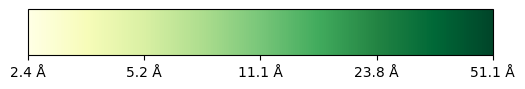

In [ ]:
def get_top_n_avg_distances(df, n, n_residues, dist_col_prefix='ag_res'):
    """
    Average per-residue min distance to the antibody
    over the top-n ipTM predictions.
    """
    top = df.nlargest(n, 'iptm')
    dist_cols = [f'{dist_col_prefix}_{i}_min_dist' for i in range(1, n_residues + 1)]
    return top[dist_cols].mean()


def distances_to_color(avg_distances, colormap):
    """Uses log-scaled distances to assign colors to the chain."""
    log_dist = np.log(avg_distances.values.astype(float))
    lo, hi = log_dist.min(), log_dist.max()
    normalized = (log_dist - lo) / (hi - lo) if hi > lo else np.zeros_like(log_dist)
    cmap = mpl.colormaps[colormap]
    return [mpl.colors.to_hex(cmap(v)) for v in normalized]


def visualize_residue_heatmap(
                                df,
                                cif_path,
                                n_top,
                                max_resi,
                                antigen_chain='B'
                            ):
    """
    Color the antigen chain by the log-scaled per-residue average of min distance 
    to the antibody across the top-n ipTM-ranked predictions.
    """
    avg_distances = get_top_n_avg_distances(df, n_top, n_residues=max_resi)
    hex_colors = distances_to_color(avg_distances, colormap='YlGn')

    struct = MMCIFParser(QUIET=True).get_structure("ref", cif_path)
    cif_data = to_cif_string(trim_structure(struct, {antigen_chain: max_resi}))

    view = py3Dmol.view(width=1000, height=1000)
    view.removeAllModels()
    view.addModel(cif_data, 'cif')

    view.setStyle({'chain': 'H'}, {})
    view.setStyle({'chain': 'L'}, {})

    view.setStyle({'chain': antigen_chain}, {'cartoon': {'color': '#cccccc', 'specular': False}})

    for i, hex_color in enumerate(hex_colors, start=1):
        view.addStyle(
            {'chain': antigen_chain, 'resi': [i]},
            {'cartoon': {'color': hex_color, 'specular': False}},
        )

    view.setBackgroundColor('white')
    view.zoomTo()
    view.show()

    log_vals = np.log(avg_distances.values.astype(float))
    fig, ax = plt.subplots(figsize=(6, 0.6))
    sm = plt.cm.ScalarMappable(
        cmap=mpl.colormaps['YlGn'],
        norm=mpl.colors.Normalize(vmin=log_vals.min(), vmax=log_vals.max()),
    )
    sm.set_array([])
    cb = fig.colorbar(sm, cax=ax, orientation='horizontal')
    tick_vals = np.linspace(log_vals.min(), log_vals.max(), 5)
    cb.set_ticks(tick_vals)
    cb.set_ticklabels([f'{np.exp(v):.1f} Å' for v in tick_vals])
    plt.show()


visualize_residue_heatmap(df, BASE_CIF, n_top=30, max_resi=RES_CUTOFF['B'])

# Figure 3C

In [7]:
with open(BASE_CIF, "r") as file:
    cif_data = file.read()
    
CDR3_heavy_range = ["95-108"]

view = py3Dmol.view(width=1000, height=1000)
view.removeAllModels()
view.addModel(cif_data, "cif")

view.setStyle({'chain': 'H'}, {'cartoon': {'color': '#4a148c', 'opacity': CDR_OPACITY, 'specular': False}})
view.setStyle({'chain': 'H', 'resi': CDR3_heavy_range}, {'cartoon': {'color': "#4a148c", 'specular': False}})
view.setStyle({'chain': 'L'}, {})
view.setStyle({'chain': 'B'}, {'cartoon': {'color': '#94ee99', 'opacity': CDR_OPACITY, 'specular': False}})

### ------ Base of the residue (without uniprot adjustment - 41) ----- ###
bond_residues_ag = [25, 34, 61]
bond_residues_hc = [74, 105]

view.addStyle({'chain': 'H', 'resi': bond_residues_hc}, {'stick': {'color': "#f0921f", 'specular': False, 'radius': 0.25}})
view.addStyle({'chain': 'H', 'resi': bond_residues_hc}, {'cartoon': {'color': "#f0921f", 'specular': False}})
view.addStyle({'chain': 'B', 'resi': bond_residues_ag}, {'stick': {'color': "#ff0000", 'specular': False, 'radius': 0.25}})
view.addStyle({'chain': 'B', 'resi': bond_residues_ag}, {'cartoon': {'color': "#ff0000", 'specular': False}})

view.setBackgroundColor('white')
view.zoomTo() 

view.show()

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

# Supplementary Figure 1

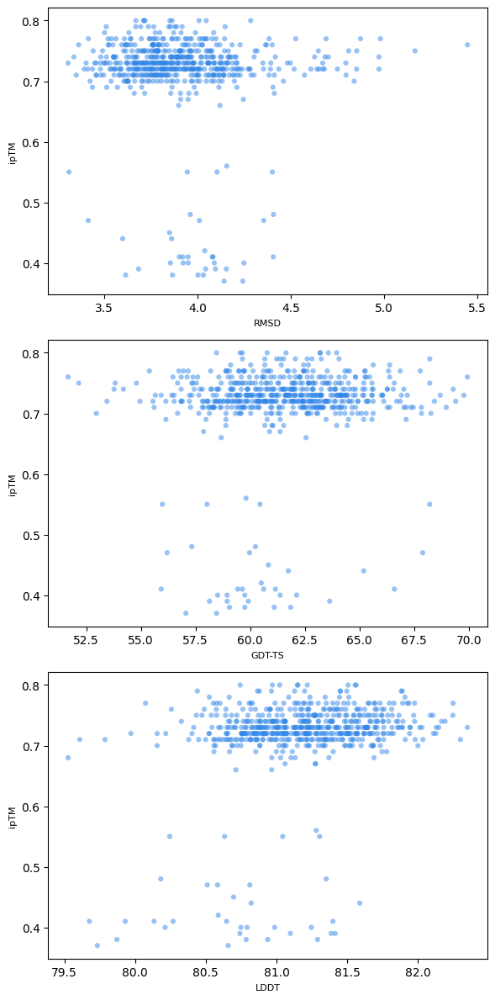

distance_metric   n  spearman_rho
           RMSD 600     -0.066175
         GDT-TS 600      0.049292
           LDDT 600      0.199324


In [8]:
list_distance_metrics = ["ag_align_rmsd_overall",
                         "ag_align_gdt_ts_overall",
                         "ag_align_lddt_overall"]

DISTANCE_LABELS = {
    "ag_align_rmsd_overall": "RMSD",
    "ag_align_gdt_ts_overall": "GDT-TS",
    "ag_align_lddt_overall": "LDDT",
}

spearman_rows = []

fig, axes = plt.subplots(len(list_distance_metrics), 1, figsize=(6, 12))
for ax, x_col in zip(axes, list_distance_metrics):
    pair = df[[x_col, "iptm"]].apply(pd.to_numeric, errors="coerce").dropna()
    rho, __ = spearmanr(pair[x_col], pair["iptm"])
    spearman_rows.append({
        "distance_metric": DISTANCE_LABELS[x_col],
        "n": len(pair),
        "spearman_rho": rho
    })

    ax.scatter(pair[x_col], pair["iptm"], alpha=0.5, s=20,
               edgecolors="none", color="#3387e8")
    ax.set_xlabel(DISTANCE_LABELS[x_col], fontsize=8)
    ax.set_ylabel("ipTM", fontsize=8)

plt.tight_layout()
plt.show()

print(pd.DataFrame(spearman_rows).to_string(index=False))

# Supplementary Figure 3

In [9]:
with open(BASE_CIF, "r") as file:
    cif_data = file.read()
    
CDR3_light_range = ["87-96"]

view = py3Dmol.view(width=1000, height=1000)
view.removeAllModels()
view.addModel(cif_data, "cif")

view.setStyle({'chain': 'L'}, {'cartoon': {'color': '#ce93d8', 'opacity': CDR_OPACITY, 'specular': False}})
view.setStyle({'chain': 'L', 'resi': CDR3_light_range}, {'cartoon': {'color': "#ce93d8", 'specular': False}})
view.setStyle({'chain': 'H'}, {})
view.setStyle({'chain': 'B'}, {'cartoon': {'color': '#94ee99', 'opacity': CDR_OPACITY, 'specular': False}})

### ------ Base of the residue (without uniprot adjustment - 41) ----- ###
bond_residues_ag = [59, 81]
bond_residues_lc = [55, 93]

view.addStyle({'chain': 'L', 'resi': bond_residues_lc}, {'stick': {'color': "#f6ea4f", 'specular': False, 'radius': 0.25}})
view.addStyle({'chain': 'L', 'resi': bond_residues_lc}, {'cartoon': {'color': "#f6ea4f", 'specular': False}})
view.addStyle({'chain': 'B', 'resi': bond_residues_ag}, {'stick': {'color': "#ff0000", 'specular': False, 'radius': 0.25}})
view.addStyle({'chain': 'B', 'resi': bond_residues_ag}, {'cartoon': {'color': "#ff0000", 'specular': False}})

view.setBackgroundColor('white')
view.zoomTo() 

view.show()

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

# Supplementary Figure 4

In [10]:
# ── 1. Parse BASE, extract chain B Cα atoms/res ids ─────────────
parser = MMCIFParser(QUIET=True)
base_struct = parser.get_structure("base", BASE_CIF)
base_ca = [a for a in base_struct[0]['B'].get_atoms() if a.get_name() == 'CA']
base_res_ids = {a.get_parent().get_id()[1] for a in base_ca}

# ── helper: superimpose a full copy of BASE onto a crystal structure, via chain B ──
def superimpose_base_onto_crystal(crystal_path, name):
    crystal_struct = parser.get_structure(name, crystal_path)
    crystal_ca = [a for a in crystal_struct[0]['B'].get_atoms() if a.get_name() == 'CA']
    crystal_res_ids = {a.get_parent().get_id()[1] for a in crystal_ca}

    common = sorted(base_res_ids & {r - UNIPROT_CORRECTION for r in crystal_res_ids})
    crystal_fixed = [a for a in crystal_ca if a.get_parent().get_id()[1] - UNIPROT_CORRECTION in common]

    # fresh copy of BASE so each crystal gets its own independently-transformed structure
    base_copy = parser.get_structure(f"base_{name}", BASE_CIF)
    base_copy_ca = [a for a in base_copy[0]['B'].get_atoms() if a.get_name() == 'CA']
    base_copy_moving = [a for a in base_copy_ca if a.get_parent().get_id()[1] in common]

    si = Superimposer()
    si.set_atoms(crystal_fixed, base_copy_moving)
    si.apply(list(base_copy.get_atoms()))
    print(f"BASE → {name}  RMSD on chain B: {si.rms:.3f} Å  ({len(common)} residues)")

    return crystal_struct, base_copy

# ── 2. Build MS4 complex and MQE complex (each: crystal fixed, BASE H/L aligned to it) ──
ms4_struct, base_on_ms4 = superimpose_base_onto_crystal(MS4_CIF, "ms4")
mqe_struct, base_on_mqe = superimpose_base_onto_crystal(MQE_CIF, "mqe")

# ── 3. Superimpose the MQE complex onto the MS4 complex, using chain A + chain B ─────
def get_ca_by_chain(struct, chain_id):
    return {a.get_parent().get_id()[1]: a for a in struct[0][chain_id].get_atoms() if a.get_name() == 'CA'}

ms4_A, ms4_B = get_ca_by_chain(ms4_struct, 'A'), get_ca_by_chain(ms4_struct, 'B')
mqe_A, mqe_B = get_ca_by_chain(mqe_struct, 'A'), get_ca_by_chain(mqe_struct, 'B')

common_A = sorted(set(ms4_A) & set(mqe_A))
common_B = sorted(set(ms4_B) & set(mqe_B))

ms4_fixed  = [ms4_A[r] for r in common_A] + [ms4_B[r] for r in common_B]
mqe_moving = [mqe_A[r] for r in common_A] + [mqe_B[r] for r in common_B]

si = Superimposer()
si.set_atoms(ms4_fixed, mqe_moving)
# apply the same transform to the MQE crystal AND its already-aligned BASE H/L copy
si.apply(list(mqe_struct.get_atoms()) + list(base_on_mqe.get_atoms()))
print(f"MQE complex → MS4 complex  RMSD on chain A+B: {si.rms:.3f} Å  ({len(common_A) + len(common_B)} residues)")

# ── 4. Serialize everyone to CIF strings for py3Dmol ─────────────
ms4_cif_string        = to_cif_string(ms4_struct)
base_on_ms4_cif_string = to_cif_string(base_on_ms4)
mqe_cif_string        = to_cif_string(mqe_struct)
base_on_mqe_cif_string = to_cif_string(base_on_mqe)

# ── 5. Build py3Dmol scene ─────────────
view = py3Dmol.view(width=1000, height=1000)
view.removeAllModels()

view.addModel(ms4_cif_string, "cif")
view.setStyle({'model': 0}, {})
view.setStyle({'model': 0, 'chain': 'A'}, {'cartoon': {'color': '#255627', 'specular': False}})
view.setStyle({'model': 0, 'chain': 'B'}, {'cartoon': {'color': '#94ee99', 'specular': False}})

view.addModel(base_on_ms4_cif_string, "cif")
view.setStyle({'model': 1}, {})
view.setStyle({'model': 1, 'chain': 'H'}, {'cartoon': {'color': '#4a148c', 'specular': False}})
view.setStyle({'model': 1, 'chain': 'L'}, {'cartoon': {'color': '#ce93d8', 'specular': False}})

view.addModel(mqe_cif_string, "cif")
view.setStyle({'model': 2}, {})
view.setStyle({'model': 2, 'chain': 'A'}, {'cartoon': {'color': '#255627', 'opacity': OVERLAY_OPACITY, 'specular': False}})
view.setStyle({'model': 2, 'chain': 'B'}, {'cartoon': {'color': '#94ee99', 'opacity': OVERLAY_OPACITY, 'specular': False}})

view.addModel(base_on_mqe_cif_string, "cif")
view.setStyle({'model': 3}, {})
view.setStyle({'model': 3, 'chain': 'H'}, {'cartoon': {'color': '#4a148c', 'opacity': OVERLAY_OPACITY, 'specular': False}})
view.setStyle({'model': 3, 'chain': 'L'}, {'cartoon': {'color': '#ce93d8', 'opacity': OVERLAY_OPACITY, 'specular': False}})

view.setBackgroundColor('white')
view.zoomTo()
view.show()

BASE → ms4  RMSD on chain B: 1.111 Å  (408 residues)
BASE → mqe  RMSD on chain B: 0.883 Å  (403 residues)
MQE complex → MS4 complex  RMSD on chain A+B: 4.851 Å  (807 residues)


3Dmol.js failed to load for some reason. Please check your browser console for error messages.